# Лабораторная работа №4: байесовская сеть

Датасет: [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance) с Kaggle — данные клиентов американской медицинской страховой компании и их расходов на лечение. Хочу построить байесовскую сеть, которая описывает, как возраст, пол, регион, курение и вес связаны с медицинскими расходами, и с её помощью ответить на вопросы вида «как изменится вероятность высоких расходов, если известно, что клиент курит».

Сеть строю и обучаю с помощью библиотеки `pgmpy`.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import networkx as nx
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set_theme(style="darkgrid")

# Часть 1. Данные

Датасет скачан с Kaggle (`insurance.csv`) и лежит рядом с ноутбуком.

In [2]:
data_raw = pd.read_csv("insurance.csv")

print(data_raw.shape)
data_raw.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
data_raw.info()
print("\nПропусков:", data_raw.isna().sum().sum())
print("Полных дубликатов:", data_raw.duplicated().sum())
data_raw.describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Пропусков: 0
Полных дубликатов: 1


,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


**Один объект** — один клиент медицинской страховой компании в США.

| Переменная | Что означает |
|---|---|
| `age` | возраст клиента (18–64 года) |
| `sex` | пол |
| `bmi` | индекс массы тела (вес / рост², кг/м²); от 30 — ожирение |
| `children` | число детей (иждивенцев), застрахованных по полису |
| `smoker` | курит ли клиент |
| `region` | регион проживания в США: northeast, northwest, southeast, southwest |
| `charges` | медицинские расходы клиента за год, оплаченные страховкой, $ |

**Какие зависимости могут существовать** (гипотезы до анализа):
- курение и лишний вес повышают риск болезней (сердце, лёгкие, диабет) → выше медицинские расходы;
- с возрастом людям нужно больше медицинской помощи → расходы растут с возрастом;
- с возрастом вес в среднем растёт (замедляется обмен веществ, меньше активности);
- курение может зависеть от пола (мужчины в среднем курят чаще);
- питание и образ жизни различаются по регионам → вес может зависеть от региона;
- число детей зависит от возраста, а расходы могут зависеть от числа застрахованных иждивенцев.

Пропусков нет. Один полный дубликат — скорее всего, это два разных клиента с одинаковыми характеристиками (идентификатора в таблице нет), и одна строка из 1338 на оценки вероятностей не повлияет, поэтому его не удаляю.

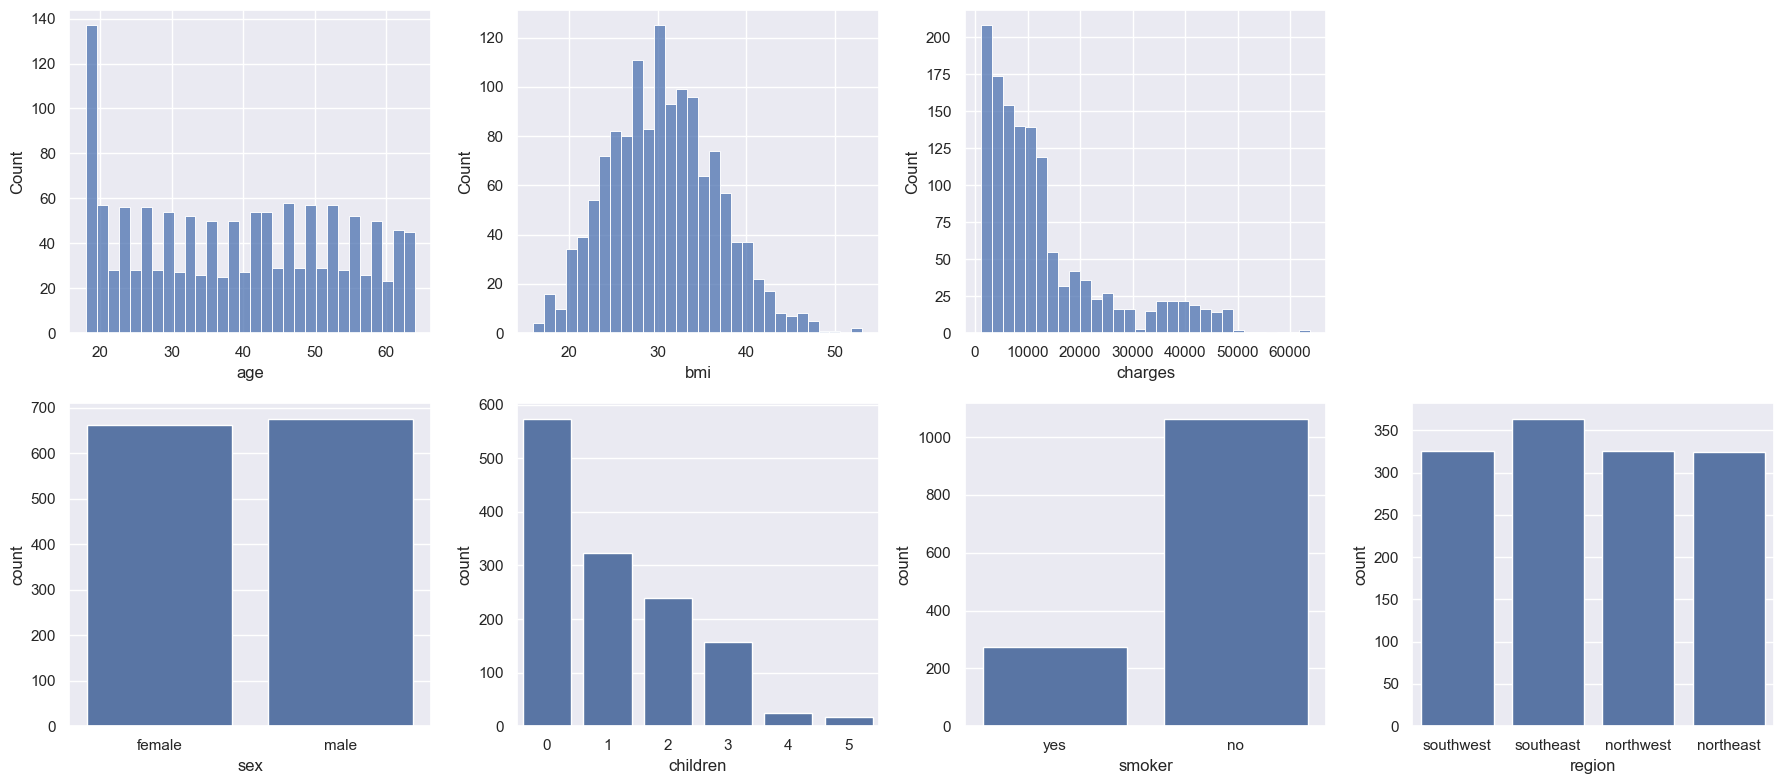

In [4]:
fig, axs = plt.subplots(figsize=(18, 8), nrows=2, ncols=4)
for i, col in enumerate(["age", "bmi", "charges"]):
    sns.histplot(data_raw[col], bins=30, ax=axs[0, i])
for i, col in enumerate(["sex", "children", "smoker", "region"]):
    sns.countplot(x=data_raw[col], color="C0", ax=axs[1, i])
axs[0, 3].axis("off")
plt.tight_layout()

Выводы по распределениям:
- `age` распределён почти равномерно от 18 до 64 лет, только 18–19-летних заметно больше.
- `bmi` близок к нормальному со средним ≈ 30.7 — больше половины клиентов с ожирением (BMI ≥ 30).
- `charges` сильно скошены вправо: медиана 9.4 тыс., но есть хвост до 64 тыс., и в нём, похоже, несколько групп (видно ниже).
- `sex` и `region` сбалансированы, курящих около 20% (274 из 1338).
- `children`: у 43% клиентов детей нет, 4 и 5 детей — редкие значения (25 и 18 клиентов).

mean   median  size
smoker obese                        
no     False   7977.0   6762.0   502
       True    8843.0   8076.0   562
yes    False  21363.0  20167.0   129
       True   41558.0  40904.0   145

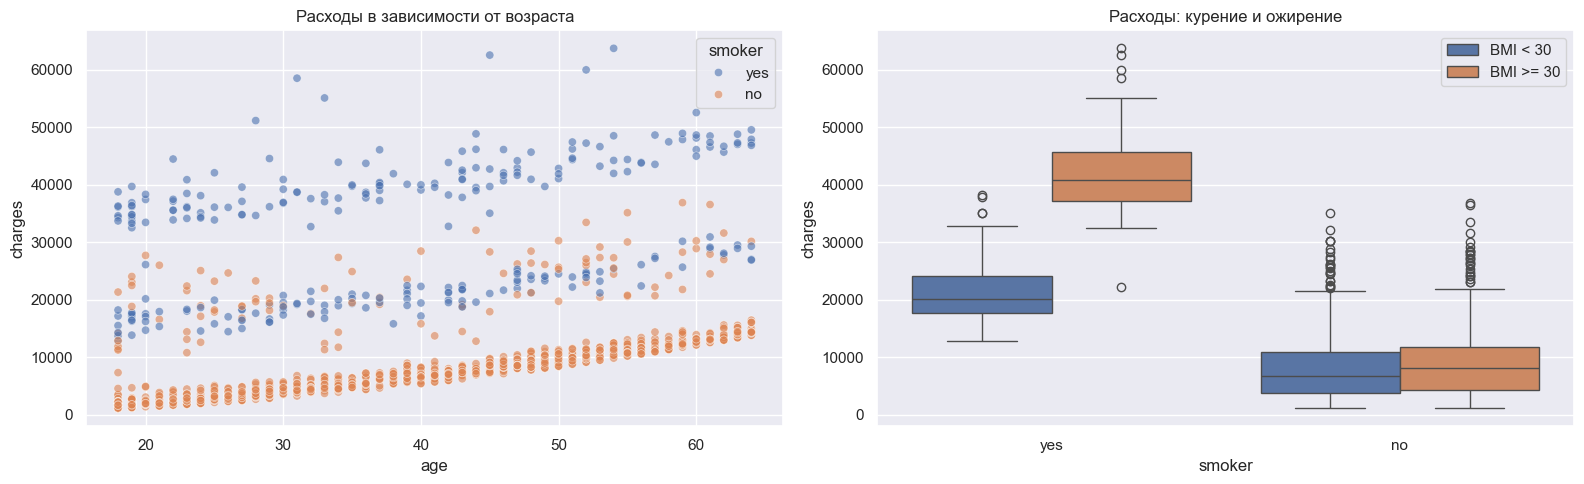

In [5]:
fig, axs = plt.subplots(figsize=(16, 5), ncols=2)
sns.scatterplot(data=data_raw, x="age", y="charges", hue="smoker", alpha=0.6, ax=axs[0])
axs[0].set_title("Расходы в зависимости от возраста")
obesity = np.where(data_raw["bmi"] >= 30, "BMI >= 30", "BMI < 30")
sns.boxplot(x=data_raw["smoker"], y=data_raw["charges"], hue=obesity, ax=axs[1])
axs[1].set_title("Расходы: курение и ожирение")
plt.tight_layout()

data_raw.assign(obese=data_raw["bmi"] >= 30).groupby(["smoker", "obese"])["charges"].agg(["mean", "median", "size"]).round(0)

Выводы:
- На графике слева видны три «полосы» расходов, и каждая растёт с возрастом: нижняя — почти только некурящие, верхняя (от ~35 тыс.) — только курящие, средняя — смесь.
- Справа видно, откуда эти полосы: **у некурящих ожирение почти не меняет расходы** (медиана 6.8 тыс. против 8.1 тыс.), а **у курящих ожирение удваивает их** (20.2 тыс. против 40.9 тыс.). Т.е. курение и ожирение действуют не по отдельности, а **усиливают друг друга** — расходы сильно растут только при их сочетании. Это важно для графа: у `charges` должны быть оба родителя, `smoker` и `bmi`. Таблица условных вероятностей задаётся для каждой комбинации родителей, поэтому такое взаимодействие сеть учтёт автоматически.
- Рост расходов с возрастом есть во всех группах — значит, `age` тоже влияет на `charges` напрямую.

In [6]:
print("Расходы в зависимости от числа детей:")
print(data_raw.groupby("children")["charges"].agg(["mean", "size"]).round(0))
print("\nДоля курящих по полу:")
print(pd.crosstab(data_raw["sex"], data_raw["smoker"], normalize="index").round(3))
print("\nСредний BMI по регионам:")
print(data_raw.groupby("region")["bmi"].mean().round(2))

Расходы в зависимости от числа детей:
             mean  size
children               
0         12366.0   574
1         12731.0   324
2         15074.0   240
3         15355.0   157
4         13851.0    25
5          8786.0    18

Доля курящих по полу:
smoker     no    yes
sex                 
female  0.826  0.174
male    0.765  0.235

Средний BMI по регионам:
region
northeast    29.17
northwest    29.20
southeast    33.36
southwest    30.60
Name: bmi, dtype: float64


Выводы:
- Число детей с расходами почти не связано: средние расходы от 8.8 до 15.4 тыс. без понятной закономерности (у 5 детей — меньше всех, но таких клиентов всего 18). Поэтому `children` в сеть не включаю: вершина без содержательных связей с остальными только усложнит граф.
- Мужчины курят чаще: 23.5% против 17.4%.
- На юго-востоке средний BMI заметно выше (33.4 против 29–31 в остальных регионах).

# Часть 2. Подготовка данных

Байесовскую сеть строю на дискретных переменных: для каждой вершины задаётся таблица условных вероятностей (CPT) по всем комбинациям значений родителей. Поэтому непрерывные признаки нужно разбить на категории. Число категорий — компромисс: чем их больше, тем подробнее описание, но тем больше параметров и тем меньше наблюдений на каждую ячейку CPT. Например, у `charges` три родителя: 3 × 3 × 2 комбинации родителей и 3 состояния — это уже 54 параметра на 1338 наблюдений.

Как дискретизирую:
- **`age`** → 3 группы: 18–29 (молодые), 30–49 (средний возраст), 50–64 (старше 50). Границы содержательные и дают примерно равные группы.
- **`bmi`** → стандартные категории ВОЗ: normal (< 25), overweight (25–30), obese (≥ 30). Категорию «недостаточный вес» (< 18.5) объединяю с normal: в ней всего 20 человек, и отдельная строка в CPT оценивалась бы очень плохо.
- **`charges`** → low (< 10 тыс.), medium (10–30 тыс.), high (≥ 30 тыс.). Граница 30 тыс. стоит там, где на гистограмме «провал» (клиентов с расходами 30–32.5 тыс. всего 8): выше неё — отдельная группа очень высоких расходов. Граница 10 тыс. — примерно медиана (9.4 тыс.): она делит большую группу умеренных расходов и отделяет дешёвых молодых некурящих от более дорогих пожилых.
- `sex`, `smoker`, `region` уже категориальные и сбалансированные — оставляю как есть.
- `children` в сеть не включаю (см. выше).

Квантильная дискретизация (например, на три равные по размеру группы) здесь хуже: границы попали бы в середину плотных групп, а не между ними.

Медиана расходов: 9382
Клиентов с расходами от 30 000 до 32 500: 8


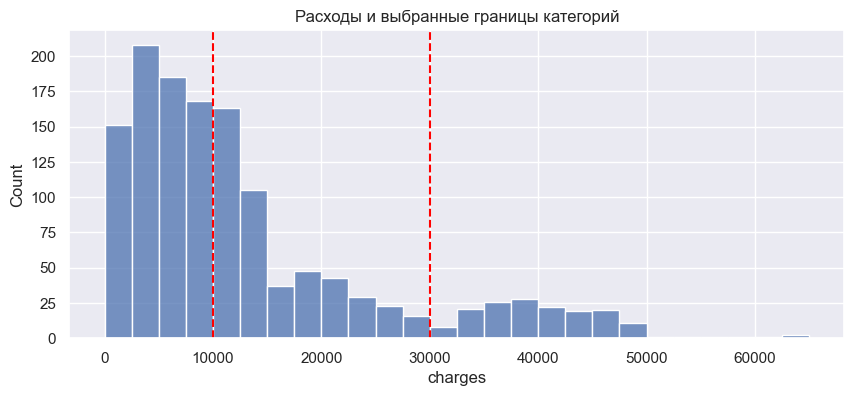

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data_raw["charges"], bins=np.arange(0, 66000, 2500), ax=ax)
for threshold in [10000, 30000]:
    ax.axvline(threshold, color="red", linestyle="--")
ax.set_title("Расходы и выбранные границы категорий")

print("Медиана расходов: %.0f" % data_raw["charges"].median())
print("Клиентов с расходами от 30 000 до 32 500: %d" % data_raw["charges"].between(30000, 32500).sum())

In [8]:
data = pd.DataFrame({
    "age": pd.cut(data_raw["age"], [18, 30, 50, 65], right=False, labels=["18-29", "30-49", "50-64"]),
    "sex": data_raw["sex"],
    "region": data_raw["region"],
    "smoker": data_raw["smoker"],
    "bmi": pd.cut(data_raw["bmi"], [0, 25, 30, 100], right=False, labels=["normal", "overweight", "obese"]),
    "charges": pd.cut(data_raw["charges"], [0, 10000, 30000, 100000], right=False, labels=["low", "medium", "high"]),
}).astype(str)

state_names = {
    "age": ["18-29", "30-49", "50-64"],
    "sex": ["female", "male"],
    "region": ["northeast", "northwest", "southeast", "southwest"],
    "smoker": ["no", "yes"],
    "bmi": ["normal", "overweight", "obese"],
    "charges": ["low", "medium", "high"],
}

for col in data.columns:
    print(col, data[col].value_counts().reindex(state_names[col]).to_dict())
print("\nНедостаточный вес (BMI < 18.5), объединён с normal:", (data_raw["bmi"] < 18.5).sum())

age {'18-29': 417, '30-49': 536, '50-64': 385}
sex {'female': 662, 'male': 676}
region {'northeast': 324, 'northwest': 325, 'southeast': 364, 'southwest': 325}
smoker {'no': 1064, 'yes': 274}
bmi {'normal': 245, 'overweight': 386, 'obese': 707}
charges {'low': 712, 'medium': 464, 'high': 162}

Недостаточный вес (BMI < 18.5), объединён с normal: 20


In [9]:
counts = data.groupby(["smoker", "bmi", "age"]).size().unstack("age")
counts = counts.reindex(index=pd.MultiIndex.from_product([state_names["smoker"], state_names["bmi"]], names=["smoker", "bmi"]), columns=state_names["age"])
print("Наблюдений на одну комбинацию родителей charges: min = %d, max = %d" % (counts.min().min(), counts.max().max()))
counts

Наблюдений на одну комбинацию родителей charges: min = 11, max = 209


age                18-29  30-49  50-64
smoker bmi                            
no     normal         79     69     42
       overweight     92    138     82
       obese         160    209    193
yes    normal         18     26     11
       overweight     23     35     16
       obese          45     59     41

Проверка данных для сети:
- **Пропусков нет**, заполнять ничего не нужно.
- **Редкие категории**: недостаточный вес (20 человек) объединён с normal; редкие значения `children` (4–5 детей) не важны, так как признак не используется. Самая маленькая категория после дискретизации — `charges = high` (162 клиента, 12%), но это как раз интересующая нас группа, и её размер достаточен.
- **Число состояний**: 2–4 у каждой переменной, всего в сети 103 параметра.
- **Достаточность наблюдений**: самая «дорогая» таблица — `P(charges | age, bmi, smoker)`, у неё 18 комбинаций родителей. В таблице выше видно, что на каждую комбинацию приходится от 11 до 209 клиентов. Меньше всего курящих с нормальным весом старше 50 (11 человек): для них вероятности оценены менее надёжно, это нужно учитывать при интерпретации. Чтобы в маленьких ячейках не получалось нулевых вероятностей, при обучении использую сглаживание (часть 5).

# Часть 3. Вопросы

До построения сети формулирую вопросы, на которые хочу ответить:
1. **Насколько курение повышает вероятность высоких расходов?** Сравнить P(charges = high) и P(charges = high | smoker = yes).
2. **Как ожирение меняет расходы у курящих и у некурящих?** Сравнить P(charges | smoker, bmi) для разных сочетаний — проверить, усиливают ли курение и ожирение друг друга.
3. **Если у клиента высокие расходы, насколько вероятно, что он курит?** Это «обратный» (диагностический) вопрос: P(smoker = yes) против P(smoker = yes | charges = high). И что при этом можно сказать о поле клиента?
4. **Влияет ли регион на расходы?** Сравнить P(charges = high | region) для разных регионов и понять, через что это влияние идёт.

# Часть 4. Граф

Предлагаю такую структуру (6 вершин, 6 рёбер):

| Ребро | Почему есть зависимость | Почему такое направление |
|---|---|---|
| `smoker → charges` | курение вызывает болезни (лёгкие, сердце, сосуды), их лечение дорогое | расходы — следствие: счёт выставляется после болезни, а не наоборот |
| `bmi → charges` | ожирение — фактор риска диабета, гипертонии, болезней сердца | то же: сначала вес, потом расходы на лечение |
| `age → charges` | с возрастом растёт число хронических болезней | возраст не может зависеть от расходов |
| `age → bmi` | с возрастом вес в среднем растёт (обмен веществ, меньше активности) | возраст не может зависеть от веса |
| `region → bmi` | питание и образ жизни различаются по регионам (на юго-востоке США ожирение распространено сильнее) | место жительства — внешний фактор для веса; обратное («полные люди переезжают на юго-восток») маловероятно |
| `sex → smoker` | мужчины в среднем курят чаще | пол задан при рождении, курение от него может зависеть, а не наоборот |

Чего в графе **нет** и почему:
- `children` — не связан с расходами (см. часть 1); без связей вершина была бы лишней.
- `age → smoker` — доля курящих одинакова во всех возрастных группах (18–22%).
- `sex → bmi`, `region → smoker`, `sex → charges` — сильных содержательных причин для прямой связи нет (например, пол может влиять на расходы, но, скорее всего, через курение). Корреляция сама по себе не повод добавлять ребро, а соответствующие независимости я проверю тестами ниже.

У `charges` три родителя (`age`, `bmi`, `smoker`): так CPT может описать и рост расходов с возрастом, и взаимодействие курения с ожирением.

In [10]:
from pgmpy.models import DiscreteBayesianNetwork

edges = [
    ("age", "bmi"),
    ("region", "bmi"),
    ("sex", "smoker"),
    ("age", "charges"),
    ("bmi", "charges"),
    ("smoker", "charges"),
]

bn = DiscreteBayesianNetwork(edges)
print("Вершины:", list(bn.nodes()))
print("Рёбер:", len(bn.edges()))
print("Ациклический граф (DAG):", nx.is_directed_acyclic_graph(bn))

Вершины: ['age', 'bmi', 'region', 'sex', 'smoker', 'charges']
Рёбер: 6
Ациклический граф (DAG): True


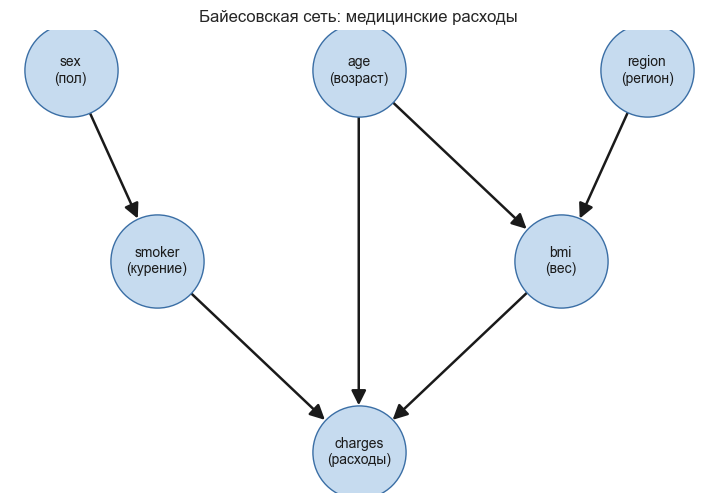

In [11]:
positions = {"sex": (0, 2), "age": (2, 2), "region": (4, 2), "smoker": (0.6, 1), "bmi": (3.4, 1), "charges": (2, 0)}
labels = {
    "sex": "sex\n(пол)", "age": "age\n(возраст)", "region": "region\n(регион)",
    "smoker": "smoker\n(курение)", "bmi": "bmi\n(вес)", "charges": "charges\n(расходы)",
}

def draw_network(model, title):
    plt.figure(figsize=(9, 6))
    nx.draw_networkx(model, pos=positions, labels=labels, node_size=4500, node_color="#c6dbef", edgecolors="#3a6ea5",
                     font_size=10, arrowsize=22, width=1.8, min_target_margin=32, min_source_margin=20)
    plt.title(title)
    plt.axis("off")

draw_network(bn, "Байесовская сеть: медицинские расходы")

Что граф утверждает о данных. В байесовской сети важны не только рёбра, но и **отсутствующие рёбра**: каждое отсутствие — это предположение о независимости. pgmpy выводит локальные независимости (каждая вершина не зависит от остальных не-потомков, если известны её родители):
- расходы не зависят от региона и пола, если известны возраст, вес и курение: регион влияет на расходы **только через вес**, пол — **только через курение**;
- курение не зависит от возраста, веса и региона, если известен пол;
- вес не зависит от пола и курения при известных возрасте и регионе.

Проверю несколько таких независимостей на данных тестом хи-квадрат (для условной независимости — внутри каждой группы условий, статистики складываются). Если p-value маленький, предположение графа противоречит данным.

In [12]:
print(bn.local_independencies(["charges", "smoker", "bmi"]))

(bmi ⟂ sex, smoker | age, region)
(charges ⟂ region, sex | age, bmi, smoker)
(smoker ⟂ age, bmi, region | sex)


In [13]:
from scipy.stats import chi2_contingency, chi2

def ci_test(x, y, given=None):
    # хи-квадрат на независимость x и y внутри каждой группы given; статистики и степени свободы складываются
    groups = [data] if given is None else [group for _, group in data.groupby(given)]
    stat, dof = 0, 0
    for group in groups:
        table = pd.crosstab(group[x], group[y])
        table = table.loc[table.sum(axis=1) > 0, table.sum(axis=0) > 0]
        if table.shape[0] > 1 and table.shape[1] > 1:
            s, _, d, _ = chi2_contingency(table, correction=False)
            stat, dof = stat + s, dof + d
    return stat, dof, chi2.sf(stat, dof)

checks = [
    ("sex", "charges", ["smoker"]),
    ("region", "charges", ["age", "bmi"]),
    ("age", "smoker", None),
    ("sex", "bmi", None),
    ("region", "smoker", None),
]

ci_table = {}
for x, y, given in checks:
    stat, dof, p_value = ci_test(x, y, given)
    name = "%s ⫫ %s" % (x, y) + (" | " + ", ".join(given) if given else "")
    ci_table[name] = {"chi2": stat, "степеней свободы": dof, "p-value": p_value}
pd.DataFrame(ci_table).T.round(4)

,chi2,степеней свободы,p-value
sex ⫫ charges | smoker,7.9769,3.0,0.0465
"region ⫫ charges | age, bmi",50.7065,51.0,0.4852
age ⫫ smoker,3.0806,2.0,0.2143
sex ⫫ bmi,3.0680,2.0,0.2157
region ⫫ smoker,7.3435,3.0,0.0617


Выводы:
- `region ⫫ charges | age, bmi` (p = 0.49), `age ⫫ smoker` (p = 0.21) и `sex ⫫ bmi` (p = 0.22) данными не опровергаются — граф с ними согласуется. Особенно важна первая: регион действительно влияет на расходы только через вес.
- `region ⫫ smoker` (p = 0.06) — на грани: на юго-востоке курящих чуть больше (25% против 18–21%). На уровне 0.05 независимость не отвергается, поэтому ребро `region → smoker` не добавляю: для него нет ни сильных данных, ни содержательной причины.
- `sex ⫫ charges | smoker` (p = 0.047) на уровне 0.05 формально отвергается, но еле-еле. Эффект маленький, а тестов я сделал пять, так что одно p-value около 0.05 вполне может быть случайным: при пяти проверках шанс хотя бы одного такого «ложного срабатывания» около 23%. Ребро `sex → charges` можно было бы добавить, но оно увеличило бы CPT расходов вдвое ради очень слабого эффекта, поэтому оставляю граф простым и отношу это к ограничениям модели.

# Часть 5. Условные вероятности

Параметры сети — это таблицы условных вероятностей P(вершина | родители). Оцениваю их по данным байесовским методом (`DiscreteBayesianEstimator`) с априорным распределением BDeu и `equivalent_sample_size=10`. По сути, это те же частоты, но к счётчикам добавляются небольшие «псевдонаблюдения», распределённые поровну между ячейками таблицы. Зачем: при обычной оценке частотами (MLE) в маленьких ячейках получаются нулевые вероятности (например, среди 11 курящих с нормальным весом старше 50 нет ни одного с высокими расходами), и сеть считала бы такие ситуации невозможными. Псевдонаблюдений всего 10 на всю таблицу, поэтому на ячейки с большим числом наблюдений сглаживание почти не влияет.

Порядок состояний задаю явно (`state_names`), чтобы в таблицах они шли по смыслу (low → medium → high), а не по алфавиту.

In [14]:
from pgmpy.parameter_estimator import DiscreteBayesianEstimator

def make_estimator():
    return DiscreteBayesianEstimator(state_names=state_names, prior_type="BDeu", equivalent_sample_size=10)

bn = bn.fit(data, estimator=make_estimator())
print("Модель корректна:", bn.check_model())
for cpd in bn.get_cpds():
    print("P(%s | %s): %d параметров" % (cpd.variable, ", ".join(cpd.variables[1:]) or "-", cpd.values.size))

Модель корректна: True
P(age | -): 3 параметров
P(bmi | age, region): 36 параметров
P(region | -): 4 параметров
P(sex | -): 2 параметров
P(smoker | sex): 4 параметров
P(charges | age, bmi, smoker): 54 параметров


In [15]:
def cpd_table(model, node):
    cpd = model.get_cpds(node)
    parents = cpd.variables[1:]
    values = cpd.values.reshape(len(cpd.state_names[node]), -1).T
    if parents:
        index = pd.MultiIndex.from_product([cpd.state_names[p] for p in parents], names=parents)
    else:
        index = ["P"]
    return pd.DataFrame(values, index=index, columns=cpd.state_names[node])

print("P(smoker | sex):")
print(cpd_table(bn, "smoker").round(3))
print("\nP(sex):")
print(cpd_table(bn, "sex").round(3))

P(smoker | sex):
           no    yes
sex                 
female  0.824  0.176
male    0.763  0.237

P(sex):
   female   male
P   0.495  0.505


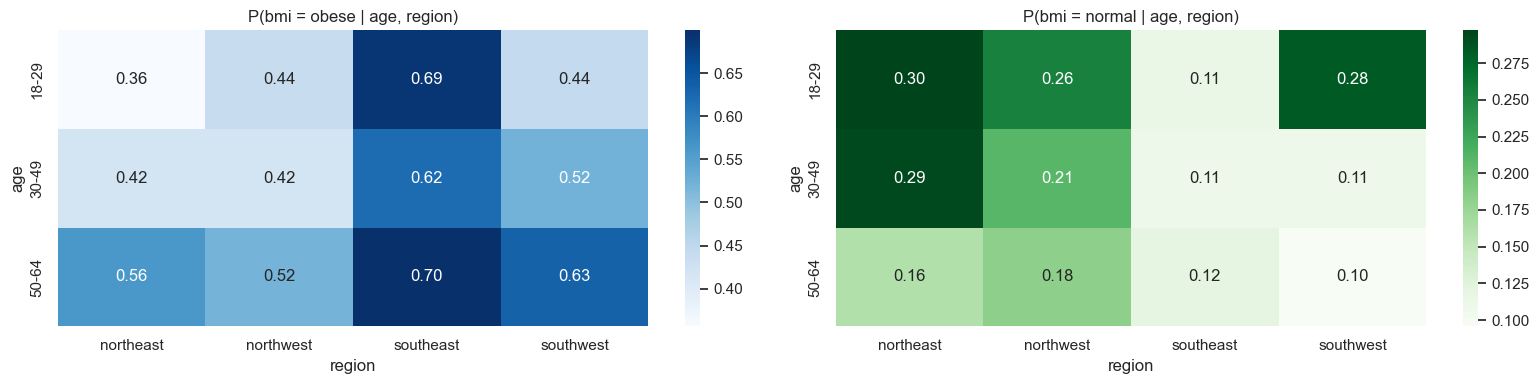

In [16]:
bmi_cpd = cpd_table(bn, "bmi")

fig, axs = plt.subplots(figsize=(16, 4), ncols=2)
sns.heatmap(bmi_cpd["obese"].unstack("region"), annot=True, fmt=".2f", cmap="Blues", ax=axs[0])
axs[0].set_title("P(bmi = obese | age, region)")
sns.heatmap(bmi_cpd["normal"].unstack("region"), annot=True, fmt=".2f", cmap="Greens", ax=axs[1])
axs[1].set_title("P(bmi = normal | age, region)")
plt.tight_layout()

Выводы по `P(smoker | sex)` и `P(bmi | age, region)`:
- Таблица курения повторяет данные: курят 17.6% женщин и 23.7% мужчин.
- Доля ожирения растёт с возрастом во всех регионах (например, на северо-востоке 0.36 → 0.42 → 0.56) — как и ожидалось.
- Юго-восток выделяется во всех возрастах: ожирение 0.62–0.70 против 0.36–0.63 в других регионах, а нормальный вес там всего у 11–12%. Это согласуется и с данными (средний BMI 33.4), и с тем, что известно о юге США (там самая высокая распространённость ожирения).
- Необычное: на юго-западе у 30–49-летних нормальный вес всего у 11%, как на юго-востоке, а у 18–29-летних — у 28%. Скорее всего, это случайность: в каждой ячейке «возраст × регион» около 100–150 клиентов, и доля 10–30% оценивается с погрешностью ±5–8 процентных пунктов.

In [17]:
charges_cpd = cpd_table(bn, "charges")
charges_cpd.round(3)

low  medium   high
age   bmi        smoker                      
18-29 normal     no      0.907   0.090  0.002
                 yes     0.010   0.980  0.010
      overweight no      0.888   0.110  0.002
                 yes     0.008   0.942  0.050
      obese      no      0.886   0.113  0.001
                 yes     0.004   0.004  0.992
30-49 normal     no      0.908   0.089  0.003
                 yes     0.007   0.911  0.082
      overweight no      0.904   0.088  0.009
                 yes     0.005   0.905  0.090
      obese      no      0.874   0.125  0.001
                 yes     0.003   0.020  0.977
50-64 normal     no      0.145   0.827  0.028
                 yes     0.016   0.968  0.016
      overweight no      0.123   0.838  0.039
                 yes     0.011   0.857  0.132
      obese      no      0.151   0.822  0.027
                 yes     0.004   0.004  0.991

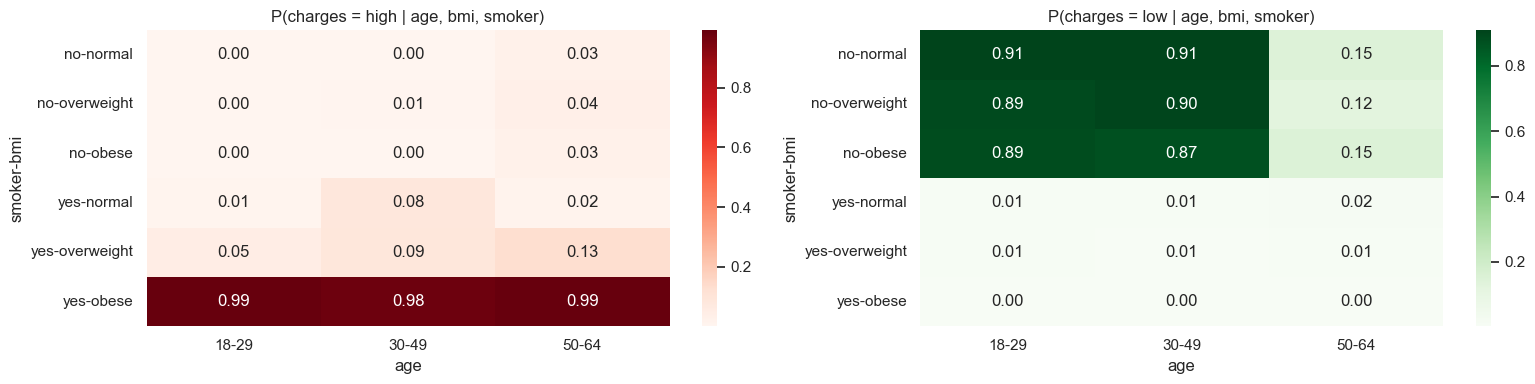

In [18]:
rows_order = pd.MultiIndex.from_product([state_names["smoker"], state_names["bmi"]], names=["smoker", "bmi"])

fig, axs = plt.subplots(figsize=(16, 4), ncols=2)
sns.heatmap(charges_cpd["high"].unstack("age").reorder_levels(["smoker", "bmi"]).reindex(rows_order), annot=True, fmt=".2f", cmap="Reds", ax=axs[0])
axs[0].set_title("P(charges = high | age, bmi, smoker)")
sns.heatmap(charges_cpd["low"].unstack("age").reorder_levels(["smoker", "bmi"]).reindex(rows_order), annot=True, fmt=".2f", cmap="Greens", ax=axs[1])
axs[1].set_title("P(charges = low | age, bmi, smoker)")
plt.tight_layout()

In [19]:
empirical = pd.crosstab([data["age"], data["bmi"], data["smoker"]], data["charges"], normalize="index").reindex(columns=state_names["charges"])
difference = (charges_cpd - empirical).abs()
print("Максимальное расхождение между CPT и частотами в данных: %.4f" % difference.max().max())
print("Среднее расхождение: %.4f" % difference.mean().mean())

Максимальное расхождение между CPT и частотами в данных: 0.0321
Среднее расхождение: 0.0059


Выводы по `P(charges | age, bmi, smoker)`:
- **Курящие с ожирением** почти наверняка попадают в высокие расходы в любом возрасте: P(high) = 0.98–0.99.
- **Курящие без ожирения** — почти всегда средние расходы (P(medium) = 0.86–0.98), высокие редко (0.01–0.13).
- **Некурящие**: вес почти ничего не меняет (до 50 лет P(low) ≈ 0.87–0.91 при любом весе), а возраст меняет сильно: после 50 лет расходы в основном средние (P(medium) ≈ 0.82–0.84). Высоких расходов у некурящих почти нет (не больше 0.04).
- Т.е. CPT подтверждает то, что было видно на графиках: курение и ожирение действуют вместе (ожирение важно только для курящих), а для некурящих главный фактор — возраст.
- **Необычное**: у курящих с нормальным весом старше 50 P(high) = 0.02, а у 30–49-летних 0.08 — как будто с возрастом высоких расходов меньше. Скорее всего, это шум: в ячейке старше 50 всего 11 клиентов и ни одного с высокими расходами (0.02 — это только сглаживание), а среди 30–49-летних таких 2 из 26. Разница — 1–2 человека.
- **Согласование с данными**: CPT отличается от частот в данных в среднем на 0.006, максимум на 0.03 (в маленьких ячейках, где заметнее сглаживание). Т.е. параметры сети почти точно повторяют данные, а отличия объясняются сглаживанием.

# Часть 6. Вероятностный вывод

Для вывода использую точный алгоритм `VariableElimination`: он считает P(переменная | evidence), суммируя совместное распределение сети по всем ненаблюдаемым переменным. Для удобства заведу функцию, которая возвращает распределение одной переменной в виде таблицы.

In [20]:
from pgmpy.inference import VariableElimination

inference = VariableElimination(bn)

def query(variable, evidence=None, model=None):
    infer = inference if model is None else VariableElimination(model)
    result = infer.query([variable], evidence=evidence or {}, show_progress=False)
    return pd.Series(result.values, index=result.state_names[variable])

### Вопрос 1. Насколько курение повышает вероятность высоких расходов?

In [21]:
q1 = pd.DataFrame({
    "ничего не известно": query("charges"),
    "smoker = no": query("charges", {"smoker": "no"}),
    "smoker = yes": query("charges", {"smoker": "yes"}),
}).T
q1.round(3)

,low,medium,high
ничего не известно,0.537,0.341,0.123
smoker = no,0.675,0.314,0.011
smoker = yes,0.006,0.442,0.552


Ответ: в среднем P(charges = high) = 0.12, а если известно, что клиент курит, — **0.55**, т.е. в 4.5 раза больше. Если клиент не курит — всего 0.01. И наоборот, низкие расходы у курящих почти невозможны (0.006 против 0.54 в среднем). Курение — самая информативная переменная: оно одно сдвигает распределение расходов сильнее, чем любая другая.

### Вопрос 2. Как ожирение меняет расходы у курящих и у некурящих?

In [22]:
q2 = {}
for smoker in state_names["smoker"]:
    for bmi_state in state_names["bmi"]:
        q2[(smoker, bmi_state)] = query("charges", {"smoker": smoker, "bmi": bmi_state})
q2 = pd.DataFrame(q2).T
q2.index.names = ["smoker", "bmi"]
q2.round(3)

low  medium   high
smoker bmi                             
no     normal      0.742   0.250  0.008
       overweight  0.701   0.285  0.014
       obese       0.638   0.353  0.010
yes    normal      0.010   0.951  0.039
       overweight  0.008   0.904  0.089
       obese       0.004   0.010  0.986

In [23]:
print("P(age | bmi) - почему возраст влияет на ответ, хотя его нет в evidence:")
pd.DataFrame({bmi_state: query("age", {"bmi": bmi_state}) for bmi_state in state_names["bmi"]}).T.round(3)

P(age | bmi) - почему возраст влияет на ответ, хотя его нет в evidence:


,18-29,30-49,50-64
normal,0.395,0.387,0.217
overweight,0.299,0.448,0.254
obese,0.290,0.378,0.332


Ответ:
- **У курящих** ожирение решает всё: P(high) = 0.04 при нормальном весе, 0.09 при избыточном и **0.99 при ожирении**.
- **У некурящих** P(high) ≈ 0.01 при любом весе. Немного меняется только доля низких расходов: 0.74 при нормальном весе и 0.64 при ожирении.

Интересно, почему у некурящих ожирение всё-таки снижает P(low), хотя в CPT вес для них почти ничего не меняет. Причина в структуре сети: `age` — общий родитель `bmi` и `charges`. Если известно, что у человека ожирение, то, по сети, он вероятнее старше (P(age = 50-64 | obese) = 0.33 против 0.22 при нормальном весе), а пожилые некурящие тратят больше. Т.е. вероятность меняется по пути `bmi ← age → charges`, а не из-за прямого влияния веса. Сеть сама учитывает такие «обходные» пути, когда значение общего родителя неизвестно.

### Вопрос 3. Если у клиента высокие расходы, насколько вероятно, что он курит?

In [24]:
q3 = pd.DataFrame({
    "P(smoker = yes)": [query("smoker")["yes"]] + [query("smoker", {"charges": state})["yes"] for state in state_names["charges"]],
    "P(sex = male)": [query("sex")["male"]] + [query("sex", {"charges": state})["male"] for state in state_names["charges"]],
}, index=["ничего не известно"] + ["charges = %s" % state for state in state_names["charges"]])
q3.round(3)

,P(smoker = yes),P(sex = male)
ничего не известно,0.207,0.505
charges = low,0.002,0.486
charges = medium,0.268,0.511
charges = high,0.931,0.572


Ответ: в среднем курят 21% клиентов, а среди клиентов с высокими расходами — **93%**. Среди клиентов с низкими расходами курящих почти нет (0.2%). Это диагностический вывод — «от следствия к причине», против направления рёбер: сеть по теореме Байеса переворачивает P(charges | smoker) в P(smoker | charges). Высокие расходы почти однозначно указывают на курение, потому что у некурящих они очень редки.

Вероятность пола при этом тоже меняется: P(мужчина) растёт с 0.505 до 0.572. Ребра между `sex` и `charges` нет, но информация проходит по цепочке `charges ← smoker ← sex`: высокие расходы → скорее курит → мужчины курят чаще → скорее мужчина.

### Вопрос 4. Влияет ли регион на расходы?

In [25]:
q4 = pd.DataFrame({"ничего не известно": query("charges"), **{region: query("charges", {"region": region}) for region in state_names["region"]}}).T
q4["P(bmi = obese)"] = [query("bmi")["obese"]] + [query("bmi", {"region": region})["obese"] for region in state_names["region"]]
q4.round(3)

,low,medium,high,P(bmi = obese)
ничего не известно,0.537,0.341,0.123,0.527
northeast,0.538,0.356,0.106,0.440
northwest,0.537,0.353,0.109,0.454
southeast,0.535,0.316,0.149,0.666
southwest,0.537,0.340,0.123,0.529


Ответ: регион влияет на расходы слабо, и только через вес. На юго-востоке P(high) = 0.15 против 0.11–0.12 в других регионах, потому что ожирение там встречается чаще (P(obese) = 0.67 против 0.44–0.53). При этом доля низких расходов во всех регионах одинаковая (≈ 0.54): у некурящих (а их большинство) вес на расходы почти не влияет, а у курящих ожирение переводит расходы из средних в высокие. Поэтому региональная разница видна только в доле высоких расходов.

### Дополнительно: что ещё можно узнать о клиенте с высокими расходами?

Высокие расходы могут объясняться разными причинами (курение, ожирение, возраст). Посмотрю, как меняется вероятность ожирения и пожилого возраста, когда известны высокие расходы, и как она меняется дальше, если узнать, курит ли клиент.

In [26]:
explain = pd.DataFrame({
    "ничего не известно": [query("bmi")["obese"], query("age")["50-64"]],
    "charges = high": [query("bmi", {"charges": "high"})["obese"], query("age", {"charges": "high"})["50-64"]],
    "charges = high, smoker = yes": [query("bmi", {"charges": "high", "smoker": "yes"})["obese"], query("age", {"charges": "high", "smoker": "yes"})["50-64"]],
    "charges = high, smoker = no": [query("bmi", {"charges": "high", "smoker": "no"})["obese"], query("age", {"charges": "high", "smoker": "no"})["50-64"]],
}, index=["P(bmi = obese)", "P(age = 50-64)"]).T
explain.round(3)

,P(bmi = obese),P(age = 50-64)
ничего не известно,0.527,0.288
charges = high,0.909,0.365
"charges = high, smoker = yes",0.941,0.332
"charges = high, smoker = no",0.474,0.812


Это пример **межпричинного вывода**: у `charges` несколько причин, и знание об одной из них меняет то, что мы думаем о других.
- Если известно только, что расходы высокие, ожирение становится очень вероятным (0.53 → 0.91), возраст 50–64 — чуть вероятнее (0.29 → 0.37).
- Если при этом клиент **курит**, ожирение становится ещё вероятнее (0.94): у курящих высокие расходы бывают почти только вместе с ожирением.
- Если клиент **не курит**, картина меняется полностью: высокие расходы у некурящего «объясняются» уже не ожирением, а возрастом — P(50–64) = 0.81, а вероятность ожирения падает до 0.47, даже ниже, чем без всякой информации. Курение было той причиной, вместе с которой ожирение даёт высокие расходы; без курения главным объяснением становится возраст.

Это работает потому, что `charges` — общее следствие (collider) нескольких причин: пока расходы неизвестны, курение и вес между собой не связаны, а как только расходы наблюдаются, причины становятся зависимыми. Цифры для некурящих с высокими расходами надо воспринимать осторожно: таких клиентов около 1% (примерно 10 человек).

# Часть 7. Эксперимент с evidence

Интересующая переменная — `charges`. Последовательно добавляю информацию о клиенте: регион, возраст, курение, вес. На последнем шаге убираю регион, оставив остальное, — чтобы проверить, что сеть действительно «забывает» регион, когда известен вес. В последнем столбце — P(ожирение) на каждом шаге, чтобы было видно, через что действует evidence.

In [27]:
steps = [
    ("1. ничего не известно", {}),
    ("2. region = southeast", {"region": "southeast"}),
    ("3. + age = 50-64", {"region": "southeast", "age": "50-64"}),
    ("4. + smoker = yes", {"region": "southeast", "age": "50-64", "smoker": "yes"}),
    ("5. + bmi = obese", {"region": "southeast", "age": "50-64", "smoker": "yes", "bmi": "obese"}),
    ("6. то же, но без region", {"age": "50-64", "smoker": "yes", "bmi": "obese"}),
]

evidence_table = pd.DataFrame({name: query("charges", evidence) for name, evidence in steps}).T
evidence_table["P(bmi = obese)"] = [query("bmi", evidence)["obese"] if "bmi" not in evidence else 1.0 for _, evidence in steps]
evidence_table.round(3)

,low,medium,high,P(bmi = obese)
1. ничего не известно,0.537,0.341,0.123,0.527
2. region = southeast,0.535,0.316,0.149,0.666
3. + age = 50-64,0.117,0.711,0.172,0.700
4. + smoker = yes,0.007,0.274,0.719,0.700
5. + bmi = obese,0.004,0.004,0.991,1.000
"6. то же, но без region",0.004,0.004,0.991,1.000


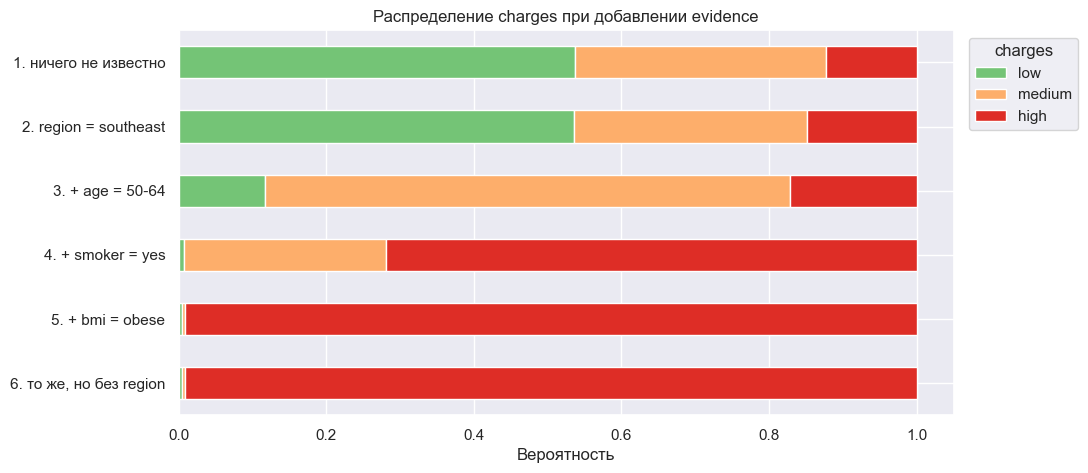

In [28]:
evidence_table[state_names["charges"]].iloc[::-1].plot(kind="barh", stacked=True, figsize=(10, 5), color=["#74c476", "#fdae6b", "#de2d26"])
plt.xlabel("Вероятность")
plt.title("Распределение charges при добавлении evidence")
plt.legend(title="charges", bbox_to_anchor=(1.01, 1), loc="upper left")

Как меняется распределение и почему (через структуру сети):
1. **Ничего не известно**: P(low, medium, high) = (0.54, 0.34, 0.12) — фактически доли в данных.
2. **region = southeast**: P(high) немного растёт (0.12 → 0.15). У региона нет прямого ребра в `charges`, влияние идёт по пути `region → bmi → charges`: на юго-востоке выше P(ожирение) (0.53 → 0.67).
3. **+ age = 50–64**: сильный сдвиг из low в medium (P(low) 0.54 → 0.12). Возраст влияет напрямую (`age → charges`): у пожилых некурящих в основном средние расходы. Плюс немного через вес (P(obese) 0.67 → 0.70).
4. **+ smoker = yes**: P(high) 0.17 → 0.72. Курение влияет напрямую. При этом P(obese) не меняется (0.70): пока расходы неизвестны, курение и вес в сети независимы — на пути `smoker → charges ← bmi` вершина `charges` является collider'ом и «закрывает» путь.
5. **+ bmi = obese**: P(high) = 0.99 — курящий пожилой человек с ожирением почти наверняка тратит больше 30 тыс.
6. **То же без региона**: распределение не изменилось ни в одном знаке. Когда известны возраст, вес и курение (все родители `charges`), регион уже ничего не добавляет: путь `region → bmi → charges` перекрыт наблюдаемым `bmi`. Это прямое следствие структуры графа (d-разделение).

Общая закономерность: каждая новая переменная сдвигает распределение настолько, насколько она связана с `charges` по путям графа. Дальние переменные (регион) — слабо и только через промежуточные вершины; родители `charges` — сильно; а когда известны все родители, остальные переменные становятся лишними.

# Часть 8. Анализ структуры

Удаляю ребро `bmi → charges` и повторяю вопрос 2: как ожирение меняет вероятность высоких расходов у курящих и некурящих. Для сравнения добавляю долю высоких расходов прямо в данных.

P(high), исходная сеть  P(high), без bmi -> charges  \
smoker bmi                                                           
no     normal                   0.008                        0.009   
       obese                    0.010                        0.012   
yes    normal                   0.039                        0.548   
       obese                    0.986                        0.559   

               доля high в данных  
smoker bmi                         
no     normal               0.005  
       obese                0.009  
yes    normal               0.036  
       obese                0.993

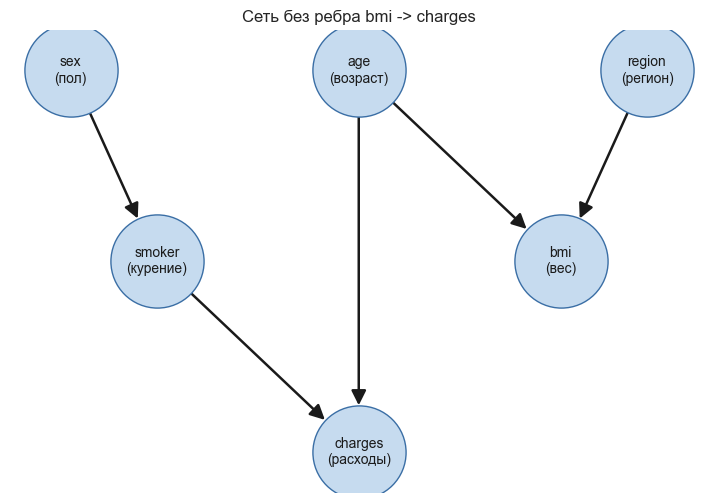

In [29]:
bn_no_edge = DiscreteBayesianNetwork([edge for edge in edges if edge != ("bmi", "charges")])
bn_no_edge = bn_no_edge.fit(data, estimator=make_estimator())

draw_network(bn_no_edge, "Сеть без ребра bmi -> charges")

compare = {}
for smoker in state_names["smoker"]:
    for bmi_state in ["normal", "obese"]:
        compare[(smoker, bmi_state)] = {
            "P(high), исходная сеть": query("charges", {"smoker": smoker, "bmi": bmi_state})["high"],
            "P(high), без bmi -> charges": query("charges", {"smoker": smoker, "bmi": bmi_state}, model=bn_no_edge)["high"],
            "доля high в данных": (data.loc[(data["smoker"] == smoker) & (data["bmi"] == bmi_state), "charges"] == "high").mean(),
        }
compare = pd.DataFrame(compare).T
compare.index.names = ["smoker", "bmi"]
compare.round(3)

Результат изменился кардинально:
- В исходной сети у курящих P(high) = 0.04 при нормальном весе и 0.99 при ожирении — как в данных (0.04 и 0.99).
- Без ребра `bmi → charges` у курящих P(high) ≈ 0.55 при любом весе: сеть больше «не знает», что вес влияет на расходы, и выдаёт средний ответ для всех курящих. Для курящих с нормальным весом она завышает риск в 14 раз, для курящих с ожирением занижает почти вдвое.
- У некурящих почти ничего не изменилось: для них вес и так почти не важен.

**Почему структура влияет на вывод.** Граф определяет, как совместное распределение раскладывается на множители: P(age, sex, region, smoker, bmi, charges) = P(age)·P(sex)·P(region)·P(smoker | sex)·P(bmi | age, region)·P(charges | age, bmi, smoker). Удалив ребро, мы заменили P(charges | age, bmi, smoker) на P(charges | age, smoker), т.е. **заранее объявили**, что при известных возрасте и курении вес на расходы не влияет. Никакие данные этого уже не исправят: в таблице просто нет параметров для такой зависимости. Структура — это предположения модели, и неверное предположение даёт систематически неверные ответы.

In [30]:
from pgmpy.structure_score import BIC

def fit_structure(edge_list):
    model = DiscreteBayesianNetwork(edge_list)
    model.add_nodes_from(state_names)
    return model.fit(data, estimator=make_estimator())

structures = {
    "исходная сеть": edges,
    "без bmi -> charges": [edge for edge in edges if edge != ("bmi", "charges")],
    "smoker -> sex вместо sex -> smoker": [("smoker", "sex") if edge == ("sex", "smoker") else edge for edge in edges],
    "charges -> bmi вместо bmi -> charges": [("charges", "bmi") if edge == ("bmi", "charges") else edge for edge in edges],
}

bic = BIC(data, state_names=state_names)
score_table = {}
for name, edge_list in structures.items():
    model = fit_structure(edge_list)
    score_table[name] = {
        "BIC": bic.score(model),
        "P(smoker = yes | charges = high)": query("smoker", {"charges": "high"}, model=model)["yes"],
        "P(high | smoker = yes, bmi = obese)": query("charges", {"smoker": "yes", "bmi": "obese"}, model=model)["high"],
        "P(obese | region = southeast)": query("bmi", {"region": "southeast"}, model=model)["obese"],
    }
pd.DataFrame(score_table).T.round(4)

,BIC,P(smoker = yes | charges = high),"P(high | smoker = yes, bmi = obese)",P(obese | region = southeast)
исходная сеть,-6915.7541,0.9314,0.9860,0.6658
без bmi -> charges,-6986.3561,0.9315,0.5590,0.6658
smoker -> sex вместо sex -> smoker,-6915.7541,0.9314,0.9860,0.6658
charges -> bmi вместо bmi -> charges,-7058.3656,0.9315,0.7734,0.6438


Сравнение нескольких структур по BIC (логарифм правдоподобия данных минус штраф за число параметров; в pgmpy чем больше, тем лучше):
- **Без ребра `bmi → charges`** BIC хуже на ~71 — данные однозначно «за» это ребро.
- **`smoker → sex` вместо `sex → smoker`**: BIC и все вероятности совпадают **до последнего знака**. Это две **марковски эквивалентные** структуры: они задают одно и то же множество независимостей и одинаково хорошо описывают любые данные. Т.е. по данным в принципе нельзя определить, курение зависит от пола или «пол от курения». Направление здесь выбрано только из здравого смысла (пол задан при рождении).
- **`charges → bmi` вместо `bmi → charges`**: BIC сильно хуже (−7058 против −6916), и ответ на вопрос 2 искажается (0.77 вместо 0.99). Разворот этого ребра меняет v-структуры графа (конфигурации вида A → C ← B, где A и B не связаны): в исходном графе `charges` — общее следствие `smoker` и `bmi`, а после разворота сеть утверждает, например, что при известных расходах и возрасте вес не зависит от курения. Это противоречит данным: при одинаковых расходах у курящих и некурящих вес разный. Такие развороты данные уже различают.

**Насколько уверенно можно выбирать направление рёбер только по данным?** Не очень. По наблюдаемым данным можно определить только класс эквивалентности графа: какие пары вершин связаны и где есть v-структуры. Например, направление `age → bmi` в принципе различимо, потому что `age → bmi ← region` — v-структура (возраст и регион не связаны, но оба влияют на вес). А направление ребра `sex – smoker` данные не различают совсем, и его приходится выбирать по знанию предметной области (пол и возраст «появляются» раньше курения и веса, а расходы — последствие). К тому же данных конечное число, и даже различимые структуры надёжно различаются только при достаточно сильных эффектах.

# Часть 9. Причинность

Можно ли считать построенную сеть причинной моделью? **В целом — нет.** Байесовская сеть, обученная на наблюдательных данных, гарантированно описывает только **совместное распределение**: какие переменные зависимы и как меняются вероятности при наблюдении других переменных. Стрелки задают удобное разложение этого распределения, но:
- данные не различают направление многих рёбер (как `sex → smoker` и `smoker → sex` выше), значит, данные сами по себе не могут подтвердить, что стрелка показывает причину;
- могут быть неучтённые общие причины (конфаундеры): например, доход и образование влияют и на курение, и на вес, и на доступ к медицине (а значит, и на расходы). Если такой переменной нет в сети, наблюдаемая связь «курение — расходы» может частично объясняться ею;
- наши запросы — это условные вероятности вроде P(charges | smoker = yes), т.е. ответ на вопрос «какие расходы у тех, **кто курит**», а не «что будет с расходами, если человек **бросит** курить». Это разные вопросы, и для второго нужна причинная модель и вмешательство (do-оператор).

Некоторые рёбра я всё же считаю **правдоподобно причинными**, но на основании знаний о мире, а не данных:
- `smoker → charges` и `bmi → charges`: есть медицинские исследования, где курение и ожирение причинно связаны с болезнями, а болезни — с расходами; плюс временной порядок (сначала курение, потом счёт за лечение). Но даже здесь часть связи может быть не медицинской, а тарифной: страховые компании могут выставлять курильщикам более высокие счета;
- `age → bmi`, `age → charges`, `sex → smoker`: возраст и пол не могут быть следствием других переменных сети, поэтому направление сомнений не вызывает, но сама связь может идти через неучтённые переменные (образ жизни, доход);
- `region → bmi` — наиболее сомнительное как причинное: регион, скорее всего, лишь отражает различия в доходе, питании и составе населения.